<a href="https://colab.research.google.com/github/hpatel1933/AAI2025/blob/2026fall/TBD_agentic_support_bot.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Agentic Customer Service & Sales Assistant

## 1. Install dependencies

In [ ]:
# If pip prints a 'dependency conflicts' warning about google-auth, it is safe to ignore.
# After installing, use Runtime → Restart session once, then run the remaining cells.
%pip install -q -U langchain-google-genai
%pip install -q langgraph langchain-core


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.6/58.6 kB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 81.9/81.9 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 20.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 573.8/573.8 kB 18.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 267.9/267.9 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 869.0/869.0 kB 26.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.0 which is incompatible.


## 2. API key (Colab secrets) and model configuration

In [ ]:
import os

try:
    from google.colab import userdata
    os.environ["GOOGLE_API_KEY"] = userdata.get("GEMINI_API_KEY")
except ImportError:
    # Fallback when running outside Colab (local Jupyter, etc.)
    from getpass import getpass
    if not os.environ.get("GOOGLE_API_KEY"):
        os.environ["GOOGLE_API_KEY"] = getpass("Enter your Gemini API key: ")

# Newest Gemini model first; the next cell falls back automatically if your key can't use it.
MODEL_CANDIDATES = [
    # --- Stable text/chat models (work with tools + structured output) ---
    "gemini-4-argon",            # newest flagship reasoning model (Oct 2026)
    "gemini-3.8-flash",          # Google's recommended default for new projects
    "gemini-3.6-flash",
    "gemini-3.5-flash-lite",     # also recommended for new projects; cheapest/fastest
    "gemini-3.1-flash-lite",

    # --- Preview models (may change or be removed without much notice) ---
    "gemini-3.1-pro-preview",
    "gemini-3-flash-preview",

    # --- Legacy 2.5 family (only works if your key used these models before) ---
    "gemini-2.5-pro",
    "gemini-2.5-flash",
    "gemini-2.5-flash-lite",
]

In [ ]:
from langchain_google_genai import ChatGoogleGenerativeAI

def message_text(msg) -> str:
    """Return plain text from a message.

    Newer Gemini models can return content as a list of content blocks
    instead of a plain string; this handles both shapes.
    """
    content = msg.content
    if isinstance(content, str):
        return content
    parts = []
    for block in content:
        if isinstance(block, str):
            parts.append(block)
        elif isinstance(block, dict) and block.get("type") == "text":
            parts.append(block.get("text", ""))
    return "".join(parts)


# Pick the first model that answers a quick test call.
llm = None
for MODEL_NAME in MODEL_CANDIDATES:
    try:
        candidate = ChatGoogleGenerativeAI(model=MODEL_NAME, temperature=0)
        reply = message_text(candidate.invoke("Say hello in five words."))
        llm = candidate
        print(f"Using {MODEL_NAME}: {reply}")
        break
    except Exception as exc:
        print(f"{MODEL_NAME} unavailable ({type(exc).__name__}: {str(exc)[:120]}), trying next...")

if llm is None:
    raise RuntimeError("No Gemini model in MODEL_CANDIDATES worked. Check your API key and model access.")

gemini-4-argon unavailable (GoogleRateLimitError: Error calling model 'gemini-4-argon' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'Y), trying next...
Using gemini-3.8-flash: Hello there, how are you?


## 3. Mock business data

In [ ]:
PRODUCTS = {
    "AlphaBook Pro 14": {
        "category": "laptop",
        "price": 1299.00,
        "in_stock": True,
        "features": "14-inch 2.8K display, 16GB RAM, 1TB SSD, 18-hour battery, aluminum body, 1.4 kg",
    },
    "AlphaBook Air 13": {
        "category": "laptop",
        "price": 899.00,
        "in_stock": True,
        "features": "13-inch display, 8GB RAM, 512GB SSD, fanless silent design, 15-hour battery, 1.1 kg, lightweight for students",
    },
    "GamerX 17": {
        "category": "laptop",
        "price": 1899.00,
        "in_stock": False,
        "features": "17-inch 240Hz display, RTX graphics, 32GB RAM, 2TB SSD, RGB keyboard, built for gaming",
    },
    "SoundWave Buds": {
        "category": "headphones",
        "price": 129.00,
        "in_stock": True,
        "features": "wireless earbuds, active noise cancellation, 30-hour battery with case, water resistant",
    },
    "UltraDock USB-C Hub": {
        "category": "accessory",
        "price": 79.00,
        "in_stock": True,
        "features": "USB-C docking station, dual HDMI 4K, ethernet, SD card reader, 100W pass-through charging",
    },
}

ORDERS = {
    "ORD-1001": {"customer": "Alice", "product": "AlphaBook Pro 14", "quantity": 1, "status": "Shipped",
                 "eta": "2026-10-20"},
    "ORD-1002": {"customer": "Bob", "product": "SoundWave Buds", "quantity": 2, "status": "Pending",
                 "eta": "2026-10-24"},
    "ORD-1003": {"customer": "Carol", "product": "UltraDock USB-C Hub", "quantity": 1, "status": "Delivered",
                 "eta": "2026-10-10"},
}

## 4. Tools
### 4a. Product Q&A tools

In [ ]:
import re
from langchain_core.tools import tool


def _find_product(name: str):
    """Case-insensitive, forgiving product-name lookup."""
    name_l = name.lower().strip()
    for product_name in PRODUCTS:
        if product_name.lower() == name_l:
            return product_name
    for product_name in PRODUCTS:
        if name_l in product_name.lower() or product_name.lower() in name_l:
            return product_name
    return None


@tool
def search_products(query: str) -> str:
    """Search the product catalog by keywords such as a product name, category
    (laptop, headphones, accessory) or feature (gaming, lightweight, noise cancellation).
    Returns up to three matching products with features and stock status."""
    words = [w for w in re.findall(r"[a-z0-9]+", query.lower()) if len(w) > 2]
    hits = []
    for name, p in PRODUCTS.items():
        haystack = f"{name} {p['category']} {p['features']}".lower()
        score = sum(w in haystack for w in words)
        if score:
            hits.append((score, name, p))
    if not hits:
        return "No matching products found. Available products: " + ", ".join(PRODUCTS)
    hits.sort(key=lambda h: -h[0])
    return "\n".join(
        f"- {name} ({p['category']}): {p['features']}. In stock: {'yes' if p['in_stock'] else 'no'}"
        for _, name, p in hits[:3]
    )


@tool
def get_product_price(product_name: str) -> str:
    """Get the current price and stock availability of a specific product by name."""
    match = _find_product(product_name)
    if not match:
        return f"Product '{product_name}' not found. Available products: " + ", ".join(PRODUCTS)
    p = PRODUCTS[match]
    stock = "in stock" if p["in_stock"] else "currently out of stock"
    return f"{match} costs ${p['price']:,.2f} and is {stock}."


product_tools = [search_products, get_product_price]

### 4b. Order management tools

In [ ]:
@tool
def get_order_details(order_id: str) -> str:
    """Look up an order by its ID (format ORD-1234). Returns product, quantity, status and ETA."""
    oid = order_id.strip().upper()
    order = ORDERS.get(oid)
    if not order:
        return f"No order found with ID {oid}."
    return (f"Order {oid}: {order['quantity']} x {order['product']}, status: {order['status']}, "
            f"estimated delivery: {order['eta']}.")


@tool
def update_order_quantity(order_id: str, new_quantity: int) -> str:
    """Change the quantity of an order. Only orders with status 'Pending' can be changed."""
    oid = order_id.strip().upper()
    order = ORDERS.get(oid)
    if not order:
        return f"No order found with ID {oid}."
    if order["status"] != "Pending":
        return f"Order {oid} is '{order['status']}' and can no longer be modified."
    if new_quantity < 1:
        return "Quantity must be at least 1. To remove the order entirely, cancel it instead."
    old = order["quantity"]
    order["quantity"] = new_quantity
    return f"Order {oid} quantity updated from {old} to {new_quantity}."


@tool
def cancel_order(order_id: str) -> str:
    """Cancel an order. Only orders with status 'Pending' can be cancelled."""
    oid = order_id.strip().upper()
    order = ORDERS.get(oid)
    if not order:
        return f"No order found with ID {oid}."
    if order["status"] != "Pending":
        return f"Order {oid} is '{order['status']}' and cannot be cancelled. Offer the return process instead."
    order["status"] = "Cancelled"
    return f"Order {oid} has been cancelled."


order_tools = [get_order_details, update_order_quantity, cancel_order]

## 5. Specialist agents

In [ ]:
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage
from langgraph.graph import StateGraph, MessagesState, START, END
from langgraph.prebuilt import ToolNode, tools_condition


def build_tool_agent(system_prompt: str, tools: list):
    """Build a compiled ReAct-style agent graph with a system prompt and tools."""
    llm_with_tools = llm.bind_tools(tools)

    def agent_node(state: MessagesState):
        response = llm_with_tools.invoke([SystemMessage(content=system_prompt)] + state["messages"])
        return {"messages": [response]}

    graph = StateGraph(MessagesState)
    graph.add_node("agent", agent_node)
    graph.add_node("tools", ToolNode(tools))
    graph.add_edge(START, "agent")
    graph.add_conditional_edges("agent", tools_condition)  # → "tools" if tool calls, else END
    graph.add_edge("tools", "agent")
    return graph.compile()


PRODUCT_PROMPT = """You are a friendly, knowledgeable sales assistant for TechNova Store.
- Use the tools to answer questions about products, features, prices and stock. Never invent specs or prices.
- Recommend products that fit the customer's stated needs and budget, and briefly explain why.
- If a product is out of stock, suggest the closest in-stock alternative.
- First-time customers can use code WELCOME10 for 10% off; mention it when someone seems ready to buy.
- Keep answers concise (a few sentences or a short list)."""

ORDERS_PROMPT = """You are a customer service agent for TechNova Store handling existing orders.
- Use the tools to look up, modify or cancel orders. Never guess order details.
- If the customer hasn't given an order ID, ask for it (format ORD-1234). Use earlier messages
  in the conversation to recover an order ID the customer already mentioned.
- Before cancelling an order, make sure the customer clearly asked to cancel.
- Only Pending orders can be changed or cancelled; explain this politely when it applies.
- Be empathetic and concise."""

product_agent = build_tool_agent(PRODUCT_PROMPT, product_tools)
orders_agent = build_tool_agent(ORDERS_PROMPT, order_tools)

## 6. Router + supervisor graph

In [ ]:
from typing import Literal
from pydantic import BaseModel, Field
from langgraph.checkpoint.memory import MemorySaver


class SupportState(MessagesState):
    route: str


class RouteDecision(BaseModel):
    """Which specialist should handle the customer's latest message."""
    route: Literal["product", "orders", "general"] = Field(
        description=(
            "product: questions about products, features, prices, stock, recommendations, buying. "
            "orders: anything about an existing order: status, tracking, changing quantity, cancelling. "
            "general: greetings, thanks, store policies, or anything else."
        )
    )
    reason: str = Field(description="One short sentence explaining the choice.")


ROUTER_PROMPT = """You route customer messages for TechNova Store to the right specialist.
Read the recent conversation and classify the customer's LATEST message.
Follow-ups ("what about its price?", "change it to 3") belong to the same topic as the earlier turn."""

router_llm = llm.with_structured_output(RouteDecision)


def router_node(state: SupportState):
    # Render the recent turns as a transcript so the router sees context without
    # depending on the provider's rules for message ordering.
    recent = state["messages"][-6:]
    transcript = "\n".join(
        f"{'Customer' if isinstance(m, HumanMessage) else 'Assistant'}: {message_text(m)}" for m in recent
    )
    try:
        decision = router_llm.invoke([
            SystemMessage(content=ROUTER_PROMPT),
            HumanMessage(content=f"Conversation:\n{transcript}\n\nClassify the latest customer message."),
        ])
        route = decision.route if decision else "general"
    except Exception as exc:  # structured output can occasionally fail to parse
        print(f"(router fallback: {exc})")
        route = "general"
    return {"route": route}


def make_specialist_node(agent, label: str):
    """Wrap a specialist sub-graph so only its final answer is added to the shared history."""
    def node(state: SupportState):
        result = agent.invoke({"messages": state["messages"]})
        reply = message_text(result["messages"][-1])
        return {"messages": [AIMessage(content=reply, name=label)]}
    return node


GENERAL_PROMPT = """You are the front-desk assistant for TechNova Store (laptops, headphones, accessories).
Handle greetings, thanks and general questions. Store policies:
- Free shipping on orders over $50; standard delivery 3–5 business days.
- 30-day returns on unused items in original packaging.
- Support hours: Mon–Fri 9am–6pm PT.
If the customer needs product info or help with an order, invite them to ask about it. Be warm and brief."""


def general_node(state: SupportState):
    response = llm.invoke([SystemMessage(content=GENERAL_PROMPT)] + state["messages"])
    return {"messages": [AIMessage(content=message_text(response), name="general")]}


builder = StateGraph(SupportState)
builder.add_node("router", router_node)
builder.add_node("product_agent", make_specialist_node(product_agent, "product"))
builder.add_node("orders_agent", make_specialist_node(orders_agent, "orders"))
builder.add_node("general_agent", general_node)

builder.add_edge(START, "router")
builder.add_conditional_edges(
    "router",
    lambda state: state["route"],
    {"product": "product_agent", "orders": "orders_agent", "general": "general_agent"},
)
for node_name in ("product_agent", "orders_agent", "general_agent"):
    builder.add_edge(node_name, END)

# MemorySaver keeps every thread's message history in memory, keyed by thread_id.
app = builder.compile(checkpointer=MemorySaver())

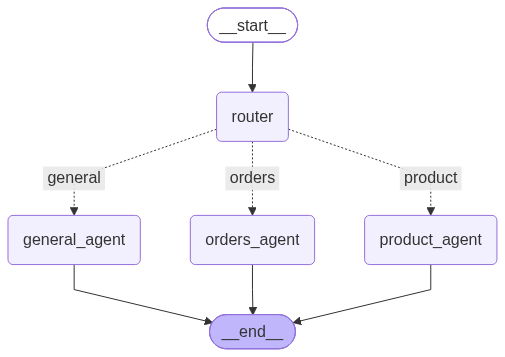

In [ ]:
# Visualize the graph (falls back to Mermaid text if rendering is unavailable)
try:
    from IPython.display import Image, display
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception:
    print(app.get_graph().draw_mermaid())

## 7. Chat helper

In [ ]:
def chat(user_input: str, thread_id: str = "demo-customer", echo: bool = True) -> str:
    """Send one message to the assistant within a conversation thread and print the reply."""
    config = {"configurable": {"thread_id": thread_id}}
    result = app.invoke({"messages": [HumanMessage(content=user_input)]}, config=config)
    reply = message_text(result["messages"][-1])
    if echo:
        print(f"🧑 You: {user_input}")
    print(f"🤖 Assistant [{result['route']}]: {reply}\n")
    return reply

## 8. Scripted demo

In [ ]:
demo_thread = "demo-customer"

chat("Hi there!", demo_thread)
chat("I'm a student looking for a lightweight laptop. What do you recommend?", demo_thread)
chat("What's its price, and is it in stock?", demo_thread)
chat("Can you check order ORD-1002 for me?", demo_thread)
chat("Please change it to 3 units.", demo_thread)
chat("What's your return policy?", demo_thread)
chat("Can I cancel ORD-1001?", demo_thread)

🧑 You: Hi there!
🤖 Assistant [general]: Hello and welcome to TechNova Store! 

How can I help you today? If you're looking for product recommendations or need assistance with an order, feel free to ask!

🧑 You: I'm a student looking for a lightweight laptop. What do you recommend?
🤖 Assistant [product]: For a student looking for portability, I highly recommend the **AlphaBook Air 13**:

* **AlphaBook Air 13** – **$899.00** (In stock)
  * **Why it's great for you:** It weighs just 1.1 kg, has a fanless silent design (ideal for libraries and classrooms), and offers up to 15 hours of battery life to get you through a full day of classes. Specs include a 13-inch display, 8GB RAM, and a 512GB SSD.

If you need more power and storage for heavier workloads, the **AlphaBook Pro 14** is also available for **$1,299.00** (1.4 kg, 16GB RAM, 1TB SSD, 18-hour battery). 

Let me know if you have any questions about either model!

🧑 You: What's its price, and is it in stock?
🤖 Assistant [product]: The

GoogleRateLimitError: Error calling model 'gemini-3.8-flash' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-3.8-flash\nPlease retry in 3h23m27.760382871s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.QuotaFailure', 'violations': [{'quotaMetric': 'generativelanguage.googleapis.com/generate_content_free_tier_requests', 'quotaId': 'GenerateRequestsPerDayPerProjectPerModel-FreeTie

In [ ]:
# Inspect the remembered conversation for this thread
state = app.get_state({"configurable": {"thread_id": demo_thread}})
print(f"Messages stored for '{demo_thread}': {len(state.values['messages'])}")
print("Order data after the demo:", ORDERS["ORD-1002"])

## 9. Interactive chat

In [ ]:
def run_chat_loop(thread_id: str = "live-session"):
    print("TechNova assistant is ready. Type 'quit' to exit.\n")
    while True:
        user_input = input("You: ").strip()
        if user_input.lower() in {"quit", "exit", "q"}:
            print("Goodbye!")
            break
        if not user_input:
            continue
        chat(user_input, thread_id, echo=False)


run_chat_loop()